# CNN Project - Submission 1: Dataset, EDA and Related Work
**Project:** Pneumonia Detection from Chest X-Ray Images Using Convolutional Neural Networks

**Group No:** 09

**Members:**
| Name | Student ID |
|---|---|
| Nayeem Ahmed | 2024-1-60-294 |
| Mahbuba Hoque Tabassum | 2023-2-60-030 |
| Sharmin Zaman Setu | 2023-3-60-476 |
| SM Erbajul Hasan | 2023-3-60-010 |

## Setup: download the dataset from Kaggle (Google Colab)

In [1]:
import os, glob, json, zipfile, subprocess, sys
from pathlib import Path


if not Path("chest_xray_data").exists():
    try:
        from google.colab import files
        print("Upload your kaggle.json file:")
        up = files.upload()
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        with open(os.path.expanduser("~/.kaggle/kaggle.json"), "wb") as f:
            f.write(up["kaggle.json"])
        os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    except ImportError:
        print("Not running in Colab - make sure kaggle.json is already set up.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "paultimothymooney/chest-xray-pneumonia",
                    "-p", "chest_xray_data", "--unzip"], check=True)
print("Download finished.")


Upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Download finished.


In [2]:
# Find the folder that contains train / test / val (the zip has a nested chest_xray folder)
def find_root(base="chest_xray_data"):
    for p in Path(base).rglob("train"):
        if p.is_dir() and (p.parent / "test").is_dir():
            return p.parent
    raise FileNotFoundError("Could not find train/test folders")

DATA_DIR = find_root()
print("Dataset root:", DATA_DIR)
print("Sub-folders:", sorted(x.name for x in DATA_DIR.iterdir() if x.is_dir()))

Dataset root: chest_xray_data/chest_xray
Sub-folders: ['__MACOSX', 'chest_xray', 'test', 'train', 'val']


## A. Dataset information

| Item | Details |
|---|---|
| **Name** | Chest X-Ray Images (Pneumonia) |
| **Source link** | https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia |
| **Original source** | Kermany et al., Mendeley Data: https://data.mendeley.com/datasets/rscbjbr9sj |
| **Licence** | CC BY 4.0 |
| **Year** | 2018 (Kermany et al., *Cell*, 2018) |
| **Task type** | Binary classification |
| **Number of classes** | 2 (NORMAL, PNEUMONIA) |
| **File format** | JPEG |
| **Patients** | Paediatric patients aged 1-5 years, Guangzhou Women and Children's Medical Center, Guangzhou, China |
| **Labelling** | Low-quality scans removed; diagnoses graded by two expert physicians, evaluation set checked by a third |

The counts, image sizes and channels below are computed from the actual files.

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

SPLITS = ["train", "val", "test"]
CLASSES = ["NORMAL", "PNEUMONIA"]
EXTS = {".jpeg", ".jpg", ".png"}

def list_images(split, cls):
    return sorted(p for p in (DATA_DIR / split / cls).rglob("*") if p.suffix.lower() in EXTS)

counts = pd.DataFrame({s: {c: len(list_images(s, c)) for c in CLASSES} for s in SPLITS})
counts["total"] = counts.sum(axis=1)
counts.loc["TOTAL"] = counts.sum()
print("Images per class and split:")
display(counts)
print("Total images:", counts.loc["TOTAL", "total"])

Images per class and split:


,train,val,test,total
NORMAL,1341,8,234,1583
PNEUMONIA,3875,8,390,4273
TOTAL,5216,16,624,5856


Total images: 5856


In [4]:
# Image size, channels (mode) and file format - checked on every image
rows = []
for s in SPLITS:
    for c in CLASSES:
        for p in list_images(s, c):
            with Image.open(p) as im:
                rows.append(dict(split=s, label=c, width=im.width, height=im.height,
                                 mode=im.mode, format=im.format, path=str(p)))
meta = pd.DataFrame(rows)
print("File formats :", dict(Counter(meta["format"])))
print("Colour modes :", dict(Counter(meta["mode"])), " (L = 1 channel grayscale, RGB = 3 channels)")
print(f"Width  : min {meta.width.min()}, max {meta.width.max()}, mean {meta.width.mean():.0f}")
print(f"Height : min {meta.height.min()}, max {meta.height.max()}, mean {meta.height.mean():.0f}")

File formats : {'JPEG': 5856}
Colour modes : {'L': 5573, 'RGB': 283}  (L = 1 channel grayscale, RGB = 3 channels)
Width  : min 384, max 2916, mean 1328
Height : min 127, max 2713, mean 971


### Why this dataset matters
Pneumonia is a leading cause of death in young children worldwide, and diagnosing it from a chest X-ray needs a trained radiologist, who are scarce in many regions, including parts of Bangladesh. An accurate CNN could act as a second reader or a triage tool and speed up diagnosis. The labels come from expert physicians and the images come from routine clinical care, so this is real medical data, which makes results more meaningful than on synthetic data.

## B. Exploratory data analysis (EDA)

### B1. Class distribution

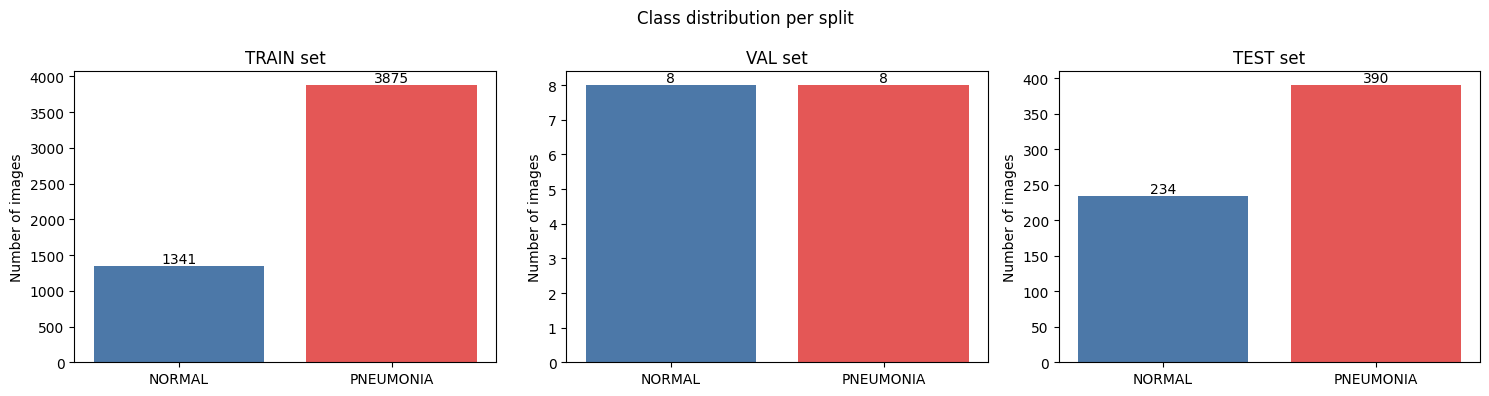

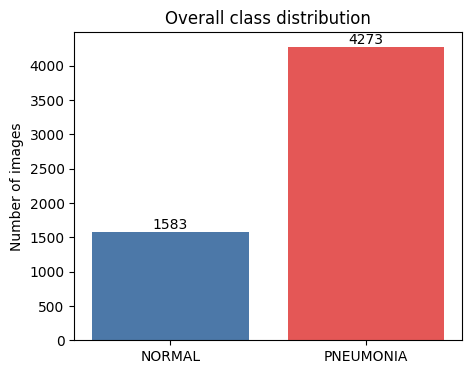

train: NORMAL  25.7% | PNEUMONIA  74.3%
val  : NORMAL  50.0% | PNEUMONIA  50.0%
test : NORMAL  37.5% | PNEUMONIA  62.5%

Train imbalance ratio (PNEUMONIA : NORMAL) = 2.89 : 1
Imbalanced? YES


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["#4C78A8", "#E45756"]
for ax, s in zip(axes, SPLITS):
    vals = [counts.loc[c, s] for c in CLASSES]
    bars = ax.bar(CLASSES, vals, color=colors)
    ax.set_title(f"{s.upper()} set")
    ax.set_ylabel("Number of images")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom")
plt.suptitle("Class distribution per split")
plt.tight_layout(); plt.show()

# Overall distribution
tot = counts.loc[CLASSES, "total"]
plt.figure(figsize=(5, 4))
bars = plt.bar(CLASSES, tot.values, color=colors)
for b, v in zip(bars, tot.values):
    plt.text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom")
plt.title("Overall class distribution"); plt.ylabel("Number of images"); plt.show()

for s in SPLITS:
    n = counts.loc[CLASSES, s]
    print(f"{s:5s}: NORMAL {n['NORMAL']/n.sum()*100:5.1f}% | PNEUMONIA {n['PNEUMONIA']/n.sum()*100:5.1f}%")
ratio = counts.loc["PNEUMONIA", "train"] / counts.loc["NORMAL", "train"]
print(f"\nTrain imbalance ratio (PNEUMONIA : NORMAL) = {ratio:.2f} : 1")
print("Imbalanced?", "YES" if ratio > 1.5 else "No")

### B2. Sample images (5 per class)

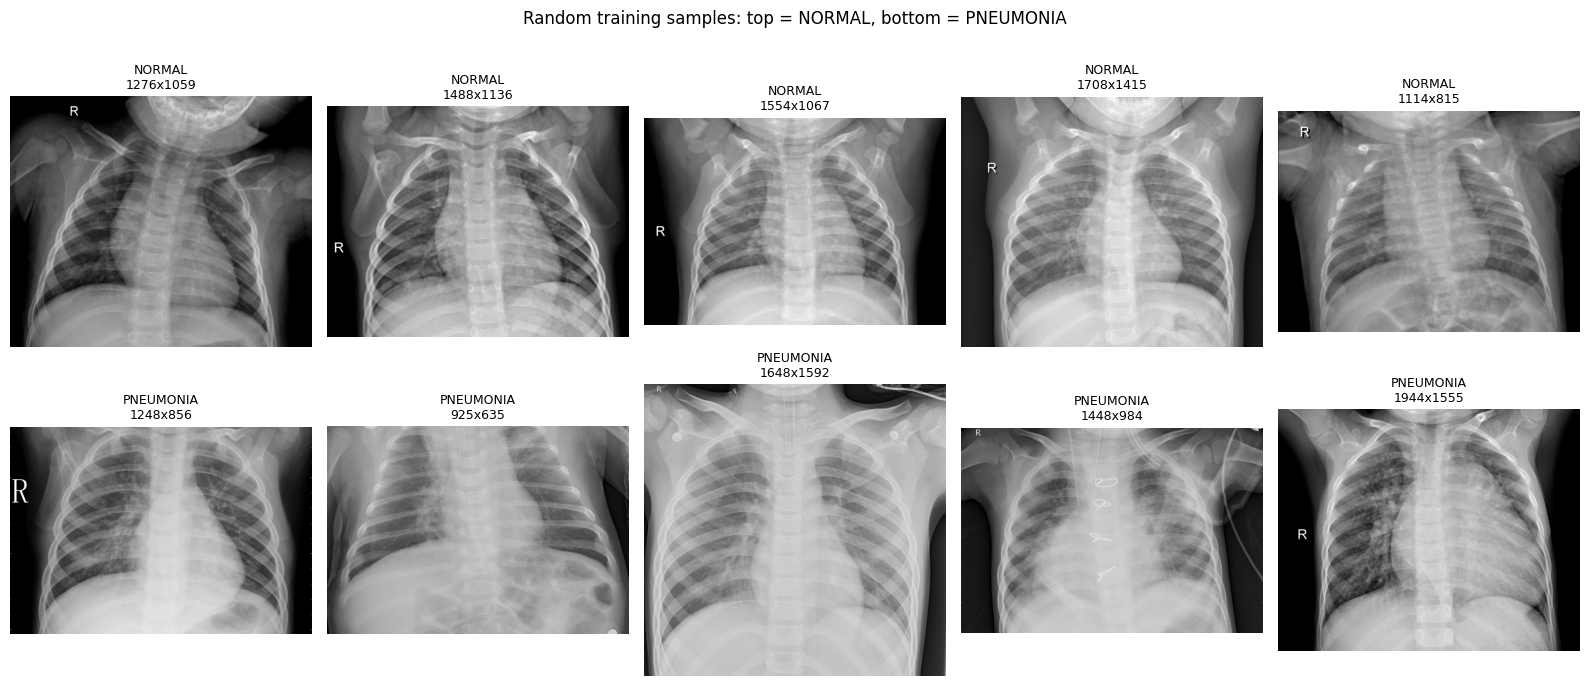

In [6]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for r, c in enumerate(CLASSES):
    paths = list_images("train", c)
    pick = rng.choice(len(paths), 5, replace=False)
    for k, i in enumerate(pick):
        img = Image.open(paths[i])
        axes[r, k].imshow(img, cmap="gray")
        axes[r, k].set_title(f"{c}\n{img.width}x{img.height}", fontsize=9)
        axes[r, k].axis("off")
plt.suptitle("Random training samples: top = NORMAL, bottom = PNEUMONIA", y=1.0)
plt.tight_layout(); plt.show()

### B3. Short findings
- **Imbalance:** The data is **imbalanced**. Training set: 1,341 NORMAL vs 3,875 PNEUMONIA (about 74% PNEUMONIA, ratio about 2.9 : 1). Accuracy alone is misleading, so we will also use precision, recall, F1 and the confusion matrix.
- **Noise:** Brightness, contrast, positioning and zoom vary between X-rays, and some images have text markers.
- **Class similarity:** Many NORMAL and PNEUMONIA images look alike, so the classes are visually similar and hard to separate.
- **Image size and channels:** Sizes vary and some images are 1-channel, some RGB.
- **Preprocessing we will use:** resize to 224x224, convert to 3 channels, scale pixels to [0, 1]. The original `val` folder has only 16 images, so we will make a new validation split from the training data.
- **Augmentation we will use:** small rotation, zoom, shift, brightness change and horizontal flip. Class weights will be used to handle the imbalance.

## C. Related work summary
Peer-reviewed journal papers on pneumonia detection from chest X-rays, all using the Kermany pediatric dataset (Guangzhou Women and Children's Medical Center) or its Kaggle copy. Results are as reported by the authors on their own splits, so they are not directly comparable.

| # | Paper (author, year) | Dataset used | Model(s) | Approach (preprocessing, augmentation, transfer learning, attention, etc.) | Result (accuracy / F1 / AUC) | Reference link |
|---|---|---|---|---|---|---|
| 1 | Stephen, Sain, Maduh, Jeong - *An Efficient Deep Learning Approach to Pneumonia Classification in Healthcare* (2019), Journal of Healthcare Engineering, article 4180949 | Kermany and Goldbaum chest X-rays, 5,856 pediatric images (ages 1-5), re-split into 3,722 train / 2,134 validation | Custom CNN from scratch: four 3x3 conv layers (32, 64, 128, 128 filters) with ReLU and max pooling, dropout 0.5, 512-unit dense layer, sigmoid output | Pixel rescaling 1/255; augmentation: rotation up to 40 degrees, shifts 0.2, shear 0.2, zoom 0.2, horizontal flip; best input size 200x200x3; no transfer learning | Training accuracy 95.31%, validation accuracy 93.73%; F1 and AUC not reported | https://pmc.ncbi.nlm.nih.gov/articles/PMC6458916 |
| 2 | Chouhan, Singh, Khamparia, Gupta, Tiwari, Moreira, Damasevicius, de Albuquerque - *A Novel Transfer Learning Based Approach for Pneumonia Detection in Chest X-ray Images* (2020), Applied Sciences 10(2): 559 | Guangzhou Women and Children's Medical Center chest X-ray dataset (Kermany) | Ensemble of five ImageNet-pretrained networks (names not given in the abstract) | Transfer learning: features extracted by each pretrained network and passed to a classifier; the outputs of all five models are combined in an ensemble | Ensemble accuracy 96.4%, recall 99.62%; F1 and AUC not reported in the abstract | https://doaj.org/article/6a3a780a05ba43018fcb77d666f69acc |
| 3 | Rahman, Chowdhury, Khandakar, Islam, Islam, Mahbub, Kadir, Kashem - *Transfer Learning with Deep Convolutional Neural Network (CNN) for Pneumonia Detection Using Chest X-Ray* (2020), Applied Sciences 10(9): 3233 | Kaggle chest X-ray pneumonia database (Kermany source), 5,247 images: 1,341 normal, 2,561 bacterial, 1,345 viral | AlexNet, ResNet18, DenseNet201, SqueezeNet | Resize 224x224 (227x227 for AlexNet and SqueezeNet) and normalise; augmentation: rotation, 10% scaling, 10% translation, each training class expanded to 4,500 images; ImageNet transfer learning; five-fold cross-validation | Best model DenseNet201, normal vs pneumonia: accuracy 98%, precision 97%, recall 99%, F1 0.981, AUC 0.98 | https://mdpi-res.com/d_attachment/applsci/applsci-10-03233/article_deploy/applsci-10-03233.pdf |
| 4 | Kundu, Das, Geem, Han, Sarkar - *Pneumonia detection in chest X-ray images using an ensemble of deep learning models* (2021), PLOS ONE 16(9): e0256630 | Kermany chest X-ray dataset (5,856 images) and RSNA Pneumonia Detection Challenge dataset | Weighted-average ensemble of GoogLeNet, ResNet-18 and DenseNet-121 | ImageNet-pretrained CNNs fine-tuned (all layers trained, Adam); ensemble weights from precision, recall, F1 and AUC; five-fold cross-validation | Kermany: accuracy 98.81%, recall 98.80%, precision 98.82%, F1 98.79%; RSNA accuracy about 86.85%; AUC shown as ROC curves | https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0256630 |
| 5 | Cha, Lee, Ko - *Attention-Based Transfer Learning for Efficient Pneumonia Detection in Chest X-ray Images* (2021), Applied Sciences 11(3): 1242 | Chest X-ray images (dataset not named in the abstract; same pneumonia detection task) | ResNet152, DenseNet121, ResNet18 as feature extractors | Transfer learning with a redefined classifier; an attention mechanism acts as a feature selector to focus on diagnostically relevant regions | Accuracy 96.63%, F-score 0.973, AUC 96.03%, precision 96.23%, recall 98.46% | https://doaj.org/article/5ecd0a5a041f412181ff236e7764ea2a |